# E2000 계열 다중 horizon 예측 전략 비교 (Direct 제외) — 리더보드 F1 + F2

**목적**: E2000 입력(111 features: ACE·27일 재귀·SUVI strip·CH·WSA-ENLIL)과 frozen XGBoost recipe(900 rounds, depth 3, lr 0.03, seed 42)를 그대로 두고 **multi-step forecasting 전략만** 바꿔, 현재 리더보드 규칙(2026-10-26~)으로 평가합니다.
- **F1**: 타깃 2026-03-01 ~ 06-01 (origin 2,137) — 모델은 **2026-02-26 이전 데이터로만 학습·튜닝**
- **F2**: 타깃 2026-06-01 ~ 09-30 (origin 2,833) — 올해 6~9월
- 순위는 F1+F2 전체 MSE, 그리고 **MSE≥550**(truth ≥ 550 km/s 셀, ffill 포함) 열을 함께 봅니다.

| 전략 | 구현 |
|---|---|
| Recursive | 1-step 공유 모델, 72회 반복 (= RecMO σ=1) |
| DirRec | h별 모델 72개 + 1..h−1 궤적 입력 (= DirRecMO σ=1) |
| MIMO | joint multi-output tree 1개가 72개 동시 출력 (= DirMO σ=72) |
| RecMO(σ) | σ-출력 공유 모델, 72/σ회 반복 |
| DirMO(σ) | 블록별 σ-출력 모델 |
| DirRecMO(σ) | 블록별 모델 + 이전 블록 궤적 입력 |
| Rectify | Recursive base + h별 residual (purged OOF base 예측으로 학습) |
| RectifyMO(σ) | RecMO base + DirMO residual, σ는 select 단계로 선택 |
| Stratify | base·residual ∈ {RecMO, DirMO, DirRecMO} × σ ∈ {6, 24}, 18개 조합 중 select 단계로 선택 |

**단계**
| stage | 학습 타깃 | 용도 |
|---|---|---|
| `select` | < 2025-12-01, 검증 origin 2025-12-04 ~ 2026-02-22 | RectifyMO σ·Stratify 조합 선택 (F1·F2 공통) |
| `f1` | < 2026-02-26 | F1 예측 |
| `final` | < 2026-05-29 | F2 예측 |

**결정사항**: ACE 계열 **2시간 지연 없음**(origin 시각 재계산, lag 2h parity 확인) · 결측 **prefill(ffill)** · 리더보드 점수는 어떤 선택에도 쓰지 않음.

In [1]:
import json, os, sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

HERE = Path(os.environ.get('FS_HOME', '/home/t-lab01/sunrun/analysis/forecast_strategies_e2000'))
sys.path.insert(0, str(HERE))
import data, evaluate, run, strategies as S

ROUNDS = int(os.environ.get('FS_ROUNDS', '0')) or None      # None -> frozen 900 rounds
SUBSAMPLE = int(os.environ.get('FS_SUBSAMPLE', '1'))          # smoke runs only
OUT = HERE / os.environ.get('FS_OUT', 'outputs')
SMOKE = ROUNDS is not None or SUBSAMPLE > 1
CFG = S.recipe(n_estimators=ROUNDS)
pd.set_option('display.width', 250, 'display.max_columns', 80)
print('config:', CFG, '| threads shared/block/workers', S.SHARED_THREADS, S.BLOCK_THREADS, S.WORKERS,
      '| subsample', SUBSAMPLE, '| out', OUT)

config: ModelConfig(horizons=72, n_estimators=900, max_depth=3, learning_rate=0.03, subsample=0.8, colsample_bytree=0.7, min_child_weight=20, reg_lambda=5, n_jobs=12) | threads shared/block/workers 12 4 6 | subsample 1 | out /home/t-lab01/sunrun/analysis/forecast_strategies_e2000/outputs


## 1. 데이터: lag-0 재계산 + prefill (train · F1 · F2 grid)

In [2]:
cache = HERE / 'outputs/cache'
if (cache / 'receipt.json').exists():
    train, f1, official, series, receipt = data.load(cache)
else:
    train, f1, official, series, receipt = data.build(cache=cache)
print(json.dumps({k: v for k, v in receipt.items() if k != 'inputs'}, indent=1))
print('train', train.C.shape, '| F1', f1.C.shape, '| F2', official.C.shape)

{
 "f1_lag2_parity": {
  "mismatch": 0,
  "origins": 256
 },
 "f1_origins": 2137,
 "lag_hours": 0,
 "nan_after_prefill": {
  "f1_C": 0,
  "f1_E": 0,
  "official_C": 0,
  "official_E": 0,
  "train_C": 13149,
  "train_E": 457920
 },
 "official_lag2_parity": {
  "mismatch": 0,
  "origins": 256
 },
 "official_origins": 2833,
 "prefill": "ffill along origin",
 "source_root": "/home/t-lab01/sunrun/data-v2/raw-store/v2/solar-pivot-noanalog72-20261015/pinned-v1/repo/leaderboard/store",
 "train_lag2_parity": {
  "mismatch": 0,
  "origins": 256
 },
 "train_origins": 10688
}
train (10688, 90) | F1 (2137, 90) | F2 (2833, 90)


## 2. select 단계 (선택 전용, 모든 데이터 < 2026-02-26)

검증 MSE는 관측 행 기준 `val_mse_obs`. RectifyMO σ와 Stratify 조합을 여기서만 고르고, 같은 선택을 F1·F2 모델에 씁니다.

In [3]:
sel = run.Stage('select', train, f1, official, series, OUT, CFG, SUBSAMPLE)
print('fit origins', len(sel.origins), '| validation origins', len(sel.Yv))
NAMES = S.STANDALONE + S.RECTIFY + S.STRATIFY
irows, ihor = {}, {}
for name in NAMES:
    t0 = time.perf_counter()
    pred = sel.run(name)
    irows[name], ihor[name] = evaluate.internal(pred, sel.Yv, sel.val_observed)
    irows[name].update(family=run.family(name), fit_seconds=sel.meta[name]['fit_seconds'])
    print(f'{name:30s} val_mse_obs={irows[name]["val_mse_obs"]:8.1f}  ({time.perf_counter() - t0:7.1f}s)', flush=True)

itable = pd.DataFrame.from_dict(irows, orient='index').sort_values('val_mse_obs')
SIGMA_RMO = run.select(irows, [n for n in S.RECTIFY if n.startswith('RectifyMO')])
STRAT = run.select(irows, S.STRATIFY)
FINAL = S.STANDALONE + ['Rectify', SIGMA_RMO, STRAT]
json.dump({'RectifyMO': SIGMA_RMO, 'Stratify': STRAT, 'canonical': run.canonical(STRAT), 'final': FINAL},
          open(OUT / 'selection.json', 'w'), indent=1)
print('selected RectifyMO:', SIGMA_RMO, '| selected Stratify:', STRAT, '->', run.canonical(STRAT))
itable.round(1)

fit origins 9232 | validation origins 648
Recursive                      val_mse_obs= 12022.5  (    0.0s)


DirRec                         val_mse_obs= 10654.1  (    0.0s)


MIMO                           val_mse_obs=  8697.6  (    0.0s)


RecMO-6                        val_mse_obs=  7608.6  (    0.0s)


RecMO-12                       val_mse_obs=  7640.0  (    0.0s)


...

Stratify-DirRecMO-RecMO-24     val_mse_obs=  9109.2  (    0.0s)


Stratify-DirRecMO-DirMO-24     val_mse_obs=  9173.7  (    0.0s)


Stratify-DirRecMO-DirRecMO-24  val_mse_obs=  8392.3  (    0.0s)


selected RectifyMO: RectifyMO-24 | selected Stratify: Stratify-DirRecMO-DirRecMO-24 -> Stratify-DirRecMO-DirRecMO-24


,val_mse_obs,val_mse_all,val_mse550_obs,val_h1-6,val_h7-24,val_h25-48,val_h49-72,family,fit_seconds
RecMO-6,7608.6,7443.0,13367.9,1512.7,5064.6,9107.4,9540.3,RecMO,164.0
RecMO-12,7640.0,7491.2,13077.0,1563.0,5089.4,9090.6,9620.2,RecMO,362.6
RecMO-24,7648.5,7509.8,13273.5,1625.0,5131.1,8907.1,9782.4,RecMO,1018.7
DirRecMO-24,7964.8,7776.4,13404.7,1710.3,5451.8,9332.1,10044.5,DirRecMO,522.8
DirRecMO-12,8067.9,7940.1,13116.0,1568.6,5393.2,9435.1,10330.1,DirRecMO,283.5
DirMO-6,8162.9,7982.6,13991.2,1530.1,5353.4,9300.5,10789.3,DirMO,1068.3
DirMO-12,8259.1,8079.8,14148.2,1568.6,5381.1,9432.9,10915.1,DirMO,1175.8
DirRecMO-6,8260.8,8147.0,13008.7,1530.1,5415.3,9694.5,10642.5,DirRecMO,468.7
DirMO-24,8341.1,8153.0,14392.1,1710.3,5451.8,9565.8,10939.6,DirMO,1008.3
Stratify-DirRecMO-DirRecMO-24,8392.3,8203.7,14401.3,1596.2,6162.3,9705.0,10449.6,Stratify,881.1


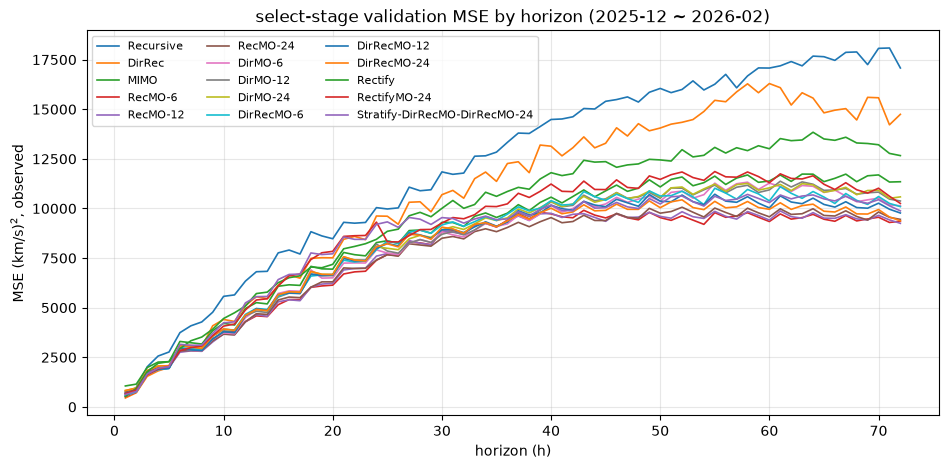

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
for name in FINAL:
    ax.plot(range(1, 73), ihor[name], label=name, lw=1.2)
ax.set(xlabel='horizon (h)', ylabel='MSE (km/s)$^2$, observed', title='select-stage validation MSE by horizon (2025-12 ~ 2026-02)')
ax.legend(ncol=3, fontsize=8); ax.grid(alpha=.3)
fig.savefig(OUT / 'select_mse_by_horizon.png', dpi=130, bbox_inches='tight'); plt.show()

## 3. F1 모델(타깃 < 2026-02-26) · F2 모델(타깃 < 2026-05-29) 학습 → F1+F2 결합 예측 357,840행

In [5]:
st_f1 = run.Stage('f1', train, f1, official, series, OUT, CFG, SUBSAMPLE)
st_f2 = run.Stage('final', train, f1, official, series, OUT, CFG, SUBSAMPLE)
scorer = evaluate.Official()
print('leaderboard store revision', scorer.revision)
rows, hor, preds, files = {}, {}, {}, {}
for name in FINAL:
    t0 = time.perf_counter()
    p1, p2 = st_f1.run(name), st_f2.run(name)
    preds[name] = np.vstack([p1, p2])
    files[name] = run.combined_file(OUT, name, st_f1, st_f2, p1, p2)
    rows[name], hor[name] = scorer.row(files[name])
    n1, n2 = len(st_f1.target_origins), len(st_f2.target_origins)
    rows[name].update(family=run.family(name), val_mse_obs=irows[name]['val_mse_obs'],
                      fit_seconds=st_f1.meta[name]['fit_seconds'] + st_f2.meta[name]['fit_seconds'],
                      inference_seconds_per_fold=(st_f1.meta[name]['inference_seconds_per_fold'] * n1
                                                  + st_f2.meta[name]['inference_seconds_per_fold'] * n2) / (n1 + n2))
    print(f'{name:30s} MSE={rows[name]["mse"]:8.1f} F1={rows[name]["mse_f1"]:8.1f} F2={rows[name]["mse_f2"]:8.1f} '
          f'MSE>=550={rows[name]["mse550"]:9.1f}  ({time.perf_counter() - t0:7.1f}s)', flush=True)

# Reference only: existing E2000 Direct multioutput run (lag 2h inputs, F2 only), same scorer on F2 folds.
for eid, label in (('E1987', 'ref:E1987 Direct multioutput (lag2h, F2 only)'),):
    found = sorted((data.ROOT / f'research/expos/runs/{eid}').glob('predictions_official*.parquet'))
    if found:
        rows[label], hor[label] = scorer.row(found[0])
        rows[label]['family'] = 'reference'

leaderboard store revision a44190559d3ca6f093eb585a31a51ddecd9580fb


Recursive                      MSE=  6043.2 F1=  6490.1 F2=  5706.1 MSE>=550=  18403.3  (    5.4s)


DirRec                         MSE=  4347.0 F1=  4772.6 F2=  4026.0 MSE>=550=  14943.0  (    5.0s)


MIMO                           MSE=  3553.6 F1=  4071.8 F2=  3162.6 MSE>=550=   9911.8  (    5.3s)


RecMO-6                        MSE=  3652.0 F1=  4102.7 F2=  3312.0 MSE>=550=  11566.7  (    5.1s)


...

DirRecMO-12                    MSE=  3534.2 F1=  3848.7 F2=  3297.0 MSE>=550=  10270.6  (    4.7s)


DirRecMO-24                    MSE=  3580.4 F1=  3958.7 F2=  3295.1 MSE>=550=  10358.1  (    5.4s)


Rectify                        MSE=  3627.8 F1=  4002.6 F2=  3345.1 MSE>=550=  10082.3  (    5.7s)


RectifyMO-24                   MSE=  3596.8 F1=  4050.9 F2=  3254.3 MSE>=550=  10281.6  ( 5860.4s)


Stratify-DirRecMO-DirRecMO-24  MSE=  3672.7 F1=  4014.1 F2=  3415.1 MSE>=550=  11862.7  ( 6507.4s)


## 4. 리더보드 (F1 + F2, 전체 MSE 오름차순)

`mse`: 순위 지표(F1+F2, ffill 포함 357,840행) · `mse_f1` / `mse_f2`: 기간별 · **`mse550`, `mse550_f1`, `mse550_f2`: truth ≥ 550 km/s 셀 MSE** (`n550` 셀 수, `bias550*` = mean(pred − truth)) · `mse550_obs`: 관측 행 중 ≥ 550 · LLH/LHH/HLH/HHH: F2 고난도 regime 4셀 · `event_f1_*`: unique-event F1 · `F2_vs_E1813_%`, `F2_vs_E1789_%`: F2 MSE 기준 상대 변화 · `val_mse_obs`: select 단계 검증(선택 근거) · `inference_seconds_per_fold`: predict 구간만.

In [6]:
board = evaluate.leaderboard(rows)
board.to_csv(OUT / 'leaderboard.csv')
fmt = {c: '{:.3f}' for c in ('skill_vs_naive', 'event_f1_F1', 'event_f1_F2')}
fmt.update({c: '{:.0f}' for c in ('n550', 'tp_F2', 'fp_F2', 'fn_F2', 'fit_seconds')})
fmt.update({'inference_seconds_per_fold': '{:.5f}'})
fmt.update({c: '{:+.2f}' for c in board.columns if c.endswith('_%')})
fmt.update({c: '{:.1f}' for c in board.columns if c not in fmt and c not in ('family', 'periods')})
with open(OUT / 'leaderboard.md', 'w') as f:
    cols = ['strategy'] + list(board.columns)
    f.write('| ' + ' | '.join(cols) + ' |\n|' + '---|' * len(cols) + '\n')
    for name, r in board.iterrows():
        vals = [name] + ['' if pd.isna(r[c]) else (fmt[c].format(r[c]) if c in fmt else str(r[c])) for c in board.columns]
        f.write('| ' + ' | '.join(vals) + ' |\n')
board.style.format(fmt, na_rep='—').background_gradient(subset=['mse', 'mse550', 'mse550_f1', 'mse550_f2'], cmap='RdYlGn_r')

,family,periods,val_mse_obs,mse,mse_f1,mse_f2,mse550,mse550_f1,mse550_f2,n550,bias550,bias550_f1,bias550_f2,mse550_obs,mse_obs,skill_vs_naive,regime_balanced_mse,csi,timing_mae_h,LLH,LHH,HLH,HHH,event_f1_F1,event_f1_F2,tp_F2,fp_F2,fn_F2,h1-6,h7-24,h25-48,h49-72,F2_vs_E1813_%,F2_vs_E1789_%,inference_seconds_per_fold,fit_seconds
strategy,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
DirMO-24,DirMO,F1+F2,8341.1,3480.3,3878.9,3179.6,10153.8,9048.1,11282.8,48456,-68.6,-53.9,-83.7,10404.2,3541.1,0.615,3155.1,0.0,5.6,4941.8,4657.2,3553.9,4023.9,0.320,0.222,3,1,20,718.6,2253.3,4089.1,4482.1,-2.98,-0.02,0.00001,1090
DirRecMO-12,DirRecMO,F1+F2,8067.9,3534.2,3848.7,3297.0,10270.6,8884.7,11685.7,48456,-67.7,-51.6,-84.1,10522.9,3599.3,0.609,3269.4,0.1,5.5,4944.0,4743.1,3486.6,4134.5,0.273,0.231,3,0,20,703.9,2267.6,4085.3,4640.7,+0.61,+3.67,0.00002,541
DirMO-12,DirMO,F1+F2,8259.1,3553.3,3960.7,3246.0,10462.0,9485.5,11459.0,48456,-69.4,-54.2,-84.9,10712.7,3609.2,0.606,3225.8,0.1,5.6,5026.5,4748.6,3652.0,4109.1,0.345,0.222,3,1,20,703.9,2292.2,4081.2,4683.7,-0.95,+2.07,0.00002,524
MIMO,MIMO,F1+F2,8697.6,3553.6,4071.8,3162.6,9911.8,9001.8,10841.0,48456,-67.0,-52.2,-82.1,10168.8,3616.5,0.606,3126.5,0.0,6.5,4680.6,4588.2,3545.1,4220.1,0.222,0.083,1,0,22,782.6,2304.9,4103.4,4633.0,-3.49,-0.55,0.00008,12922
DirMO-6,DirMO,F1+F2,8162.9,3568.3,3966.9,3267.7,10420.5,9339.1,11524.7,48456,-68.4,-52.4,-84.6,10658.4,3624.3,0.605,3249.2,0.1,5.1,5034.3,4823.3,3655.9,4170.8,0.452,0.222,3,1,20,701.8,2312.5,4113.0,4682.2,-0.29,+2.75,0.00003,339
DirRecMO-24,DirRecMO,F1+F2,7964.8,3580.4,3958.7,3295.1,10358.1,8840.2,11907.9,48456,-68.8,-53.8,-84.1,10594.8,3646.1,0.603,3236.9,0.1,6.2,4716.2,4765.0,3532.5,4432.3,0.240,0.231,3,0,20,718.6,2253.3,4158.0,4713.7,+0.55,+3.61,0.00001,1182
RecMO-12,RecMO,F1+F2,7640.0,3581.9,3962.1,3295.1,11254.5,10422.1,12104.5,48456,-75.2,-64.6,-86.1,11512.8,3642.8,0.603,3263.9,0.1,5.2,4834.4,4630.5,3534.6,4052.4,0.381,0.160,2,0,21,733.2,2425.8,4116.0,4627.1,+0.55,+3.61,0.00001,372
RectifyMO-24,RectifyMO,F1+F2,8838.0,3596.8,4050.9,3254.3,10281.6,9756.4,10817.8,48456,-68.0,-56.6,-79.7,10512.6,3652.7,0.602,3230.5,0.1,5.5,4941.9,4447.5,3718.6,4150.5,0.276,0.276,4,2,19,699.2,2348.2,4152.7,4701.9,-0.70,+2.33,0.00002,5845
DirRecMO-6,DirRecMO,F1+F2,8260.8,3606.4,3925.1,3365.9,10668.5,9074.4,12296.2,48456,-68.3,-50.4,-86.5,10921.1,3678.7,0.601,3327.9,0.0,5.2,5107.4,4866.0,3501.8,4345.7,0.417,0.214,3,2,20,701.8,2298.5,4200.5,4719.3,+2.71,+5.84,0.00003,372


## 5. 그림: horizon별 오차 전파, ≥550 구간 bias, 대표 HSS 궤적

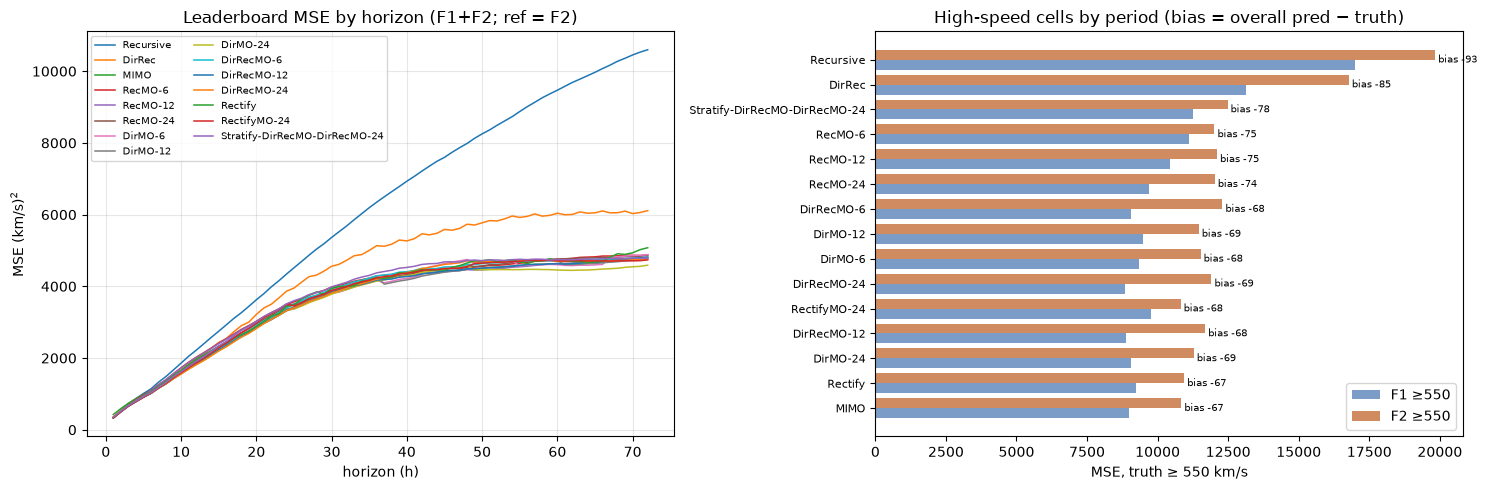

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name in FINAL + [k for k in hor if k.startswith('ref:')]:
    axes[0].plot(range(1, 73), hor[name], label=name, lw=1.6 if name.startswith('ref:') else 1.1,
                 ls='--' if name.startswith('ref:') else '-')
axes[0].set(xlabel='horizon (h)', ylabel='MSE (km/s)$^2$', title='Leaderboard MSE by horizon (F1+F2; ref = F2)'); axes[0].grid(alpha=.3)
axes[0].legend(ncol=2, fontsize=7)
b = board[~board.index.str.startswith('ref:')].sort_values('mse550')
y = np.arange(len(b))
axes[1].barh(y - .2, b['mse550_f1'], .4, label='F1 ≥550', color='#7a9cc6')
axes[1].barh(y + .2, b['mse550_f2'], .4, label='F2 ≥550', color='#d08c60')
axes[1].set_yticks(y, b.index, fontsize=8)
for i, (v, bias) in enumerate(zip(b['mse550'], b['bias550'])):
    axes[1].text(max(b['mse550_f1'].iloc[i], b['mse550_f2'].iloc[i]), i, f' bias {bias:+.0f}', va='center', fontsize=7)
axes[1].set(xlabel='MSE, truth ≥ 550 km/s', title='High-speed cells by period (bias = overall pred − truth)'); axes[1].legend()
fig.tight_layout(); fig.savefig(OUT / 'leaderboard_horizon_and_550.png', dpi=130, bbox_inches='tight'); plt.show()

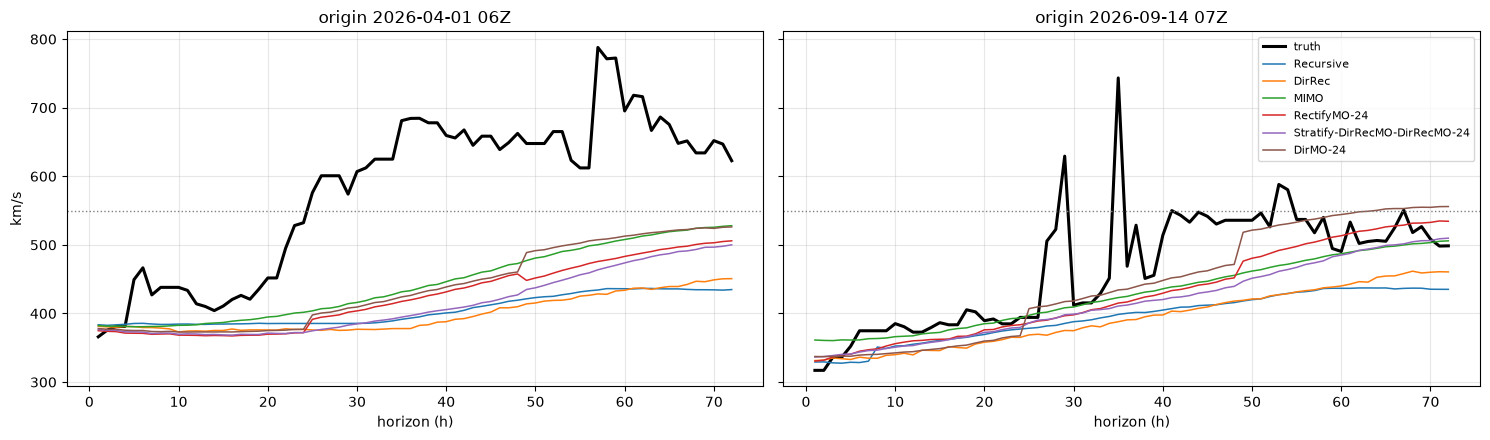

In [8]:
# Representative HSS onsets: per period, the origin with the largest 72h rise in truth (evaluation-side only).
truth = scorer.truth.assign(origin=lambda d: pd.to_datetime(d.origin_last_input_utc, utc=True))
tw = truth.pivot(index='origin', columns='horizon_hours', values='target_kms')
allo = st_f1.target_origins.append(st_f2.target_origins)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
pick = list(dict.fromkeys(['Recursive', 'DirRec', 'MIMO', SIGMA_RMO, STRAT, board.index[0]]))
for ax, period in zip(axes, (st_f1.target_origins, st_f2.target_origins)):
    rise = tw.loc[period].max(axis=1) - tw.loc[period, 1]
    o = rise.idxmax()
    i = allo.get_loc(o)
    ax.plot(range(1, 73), tw.loc[o].to_numpy(), 'k', lw=2.2, label='truth')
    for name in pick:
        if name in preds:
            ax.plot(range(1, 73), preds[name][i], lw=1.1, label=name)
    ax.axhline(550, color='gray', ls=':', lw=1); ax.set(title=f'origin {o:%Y-%m-%d %H}Z', xlabel='horizon (h)'); ax.grid(alpha=.3)
axes[0].set_ylabel('km/s'); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / 'hss_trajectories.png', dpi=130, bbox_inches='tight'); plt.show()

## 6. Loss history (round별 train/validation MSE)

모든 fit의 native per-round loss: `outputs/loss_history/<stage>/<strategy>/<model>_s42.csv` (`step,train_mse,validation_mse`). f1·final 단계의 validation은 select 검증 블록(학습 구간과 겹치는 진단용)입니다.

In [9]:
for stage in ('f1', 'final'):
    for name in dict.fromkeys(run.canonical(n) for n in FINAL):
        d = OUT / 'loss_history' / stage / name
        found = sorted(d.glob('*.csv'))
        if not found:
            continue
        fig, ax = plt.subplots(figsize=(6, 3.2))
        for f in found:
            h = pd.read_csv(f)
            ax.plot(h.step, h.validation_mse, lw=.7, alpha=.7)
        ax.set(title=f'{stage}/{name}: validation MSE per round ({len(found)} fits)', xlabel='round', ylabel='MSE', yscale='log')
        ax.grid(alpha=.3); fig.savefig(d / 'loss_history.png', dpi=110, bbox_inches='tight'); plt.close(fig)
print('loss plots written under', OUT / 'loss_history')

loss plots written under /home/t-lab01/sunrun/analysis/forecast_strategies_e2000/outputs/loss_history


## 7. 요약

In [10]:
own = board[~board.index.str.startswith('ref:')]
best, best550 = own['mse'].idxmin(), own['mse550'].idxmin()
print(f'F1+F2 MSE 최저: {best}  mse={own.loc[best, "mse"]:.1f} (F1 {own.loc[best, "mse_f1"]:.1f}, F2 {own.loc[best, "mse_f2"]:.1f}; '
      f'F2 기준 E1789 대비 {own.loc[best, "F2_vs_E1789_%"]:+.2f}%)')
print(f'MSE≥550 최저: {best550}  mse550={own.loc[best550, "mse550"]:.1f} (F1 {own.loc[best550, "mse550_f1"]:.1f}, '
      f'F2 {own.loc[best550, "mse550_f2"]:.1f}), bias550={own.loc[best550, "bias550"]:+.1f}')
print(f'select 단계 선택: RectifyMO={SIGMA_RMO}, Stratify={STRAT} -> 리더보드 순위 {list(own.index).index(STRAT) + 1}/{len(own)}')
print('리더보드 점수는 선택에 쓰지 않았습니다.' + (' [SMOKE RUN]' if SMOKE else ''))

F1+F2 MSE 최저: DirMO-24  mse=3480.3 (F1 3878.9, F2 3179.6; F2 기준 E1789 대비 -0.02%)
MSE≥550 최저: MIMO  mse550=9911.8 (F1 9001.8, F2 10841.0), bias550=-67.0
select 단계 선택: RectifyMO=RectifyMO-24, Stratify=Stratify-DirRecMO-DirRecMO-24 -> 리더보드 순위 13/15
리더보드 점수는 선택에 쓰지 않았습니다.
